In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('../data/processed/df_labeled.csv')
print(df.shape)
print(df['label'].value_counts())

(46564, 169)
label
0    42019
1     4545
Name: count, dtype: int64


In [3]:
df = df.sort_values('time_step')

train_df = df[df['time_step'] <= 34]
test_df = df[df['time_step'] > 34]

feature_columns = [col for col in df.columns if col.startswith('feature_')]

X_train = train_df[feature_columns]
y_train = train_df['label']
X_test = test_df[feature_columns]
y_test = test_df['label']

print("Train shape:", X_train.shape, "Illicit %:", y_train.mean()*100)
print("Test shape:", X_test.shape, "Illicit %:", y_test.mean()*100)

Train shape: (29894, 165) Illicit %: 11.580919248009634
Test shape: (16670, 165) Illicit %: 6.496700659868027


In [4]:
model = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    random_state=42,
    eval_metric='logloss'
)

model.fit(X_train, y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


              precision    recall  f1-score   support

       Licit       0.98      0.99      0.99     15587
     Illicit       0.91      0.72      0.81      1083

    accuracy                           0.98     16670
   macro avg       0.94      0.86      0.90     16670
weighted avg       0.98      0.98      0.98     16670



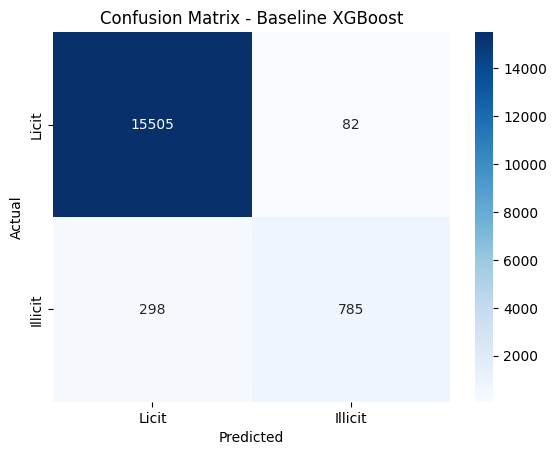

In [5]:
y_pred = model.predict(X_test)

print(classification_report(y_test, y_pred, target_names=['Licit', 'Illicit']))

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Licit','Illicit'], yticklabels=['Licit','Illicit'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Baseline XGBoost')
plt.show()

In [6]:
import numpy as np

importance = pd.Series(model.feature_importances_, index=feature_columns)
importance = importance.sort_values(ascending=False)

print(importance.head(15))

feature_5      0.497382
feature_53     0.063602
feature_46     0.045911
feature_67     0.041957
feature_90     0.036957
feature_163    0.030298
feature_22     0.021242
feature_107    0.019213
feature_59     0.013497
feature_126    0.010855
feature_80     0.010673
feature_89     0.009212
feature_103    0.007446
feature_42     0.007311
feature_147    0.007208
dtype: float32


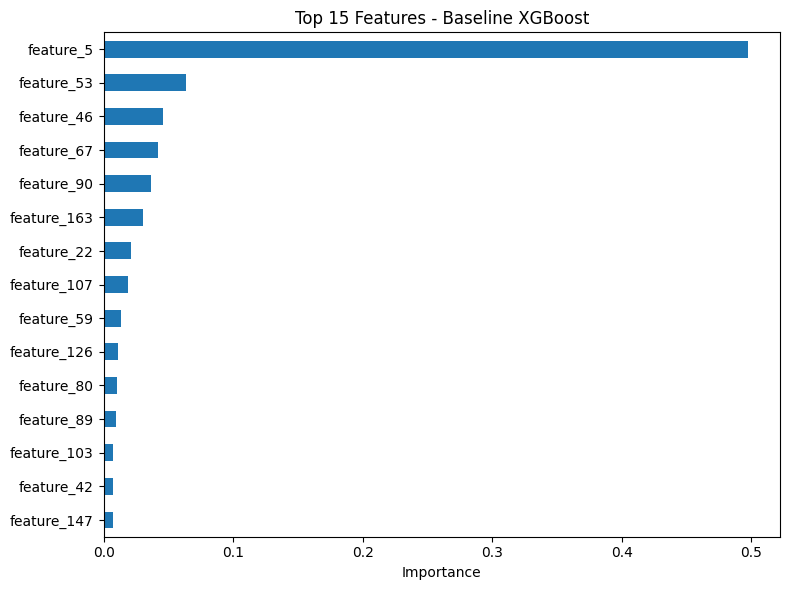

In [7]:
plt.figure(figsize=(8, 6))
importance.head(15).sort_values().plot(kind='barh')
plt.title('Top 15 Features - Baseline XGBoost')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

In [8]:
local_cols = [f'feature_{i}' for i in range(1, 94)]
agg_cols = [f'feature_{i}' for i in range(94, 166)]

print("Local features share of importance:", importance[local_cols].sum())
print("Aggregated (neighbour) features share:", importance[agg_cols].sum())

Local features share of importance: 0.85097075
Aggregated (neighbour) features share: 0.14902918


In [9]:
# Local features only vs all features
local_cols = [f'feature_{i}' for i in range(1, 94)]

m_local = XGBClassifier(n_estimators=100, max_depth=6, random_state=42, eval_metric='logloss')
m_local.fit(train_df[local_cols], y_train)
print(classification_report(y_test, m_local.predict(test_df[local_cols]), target_names=['Licit', 'Illicit']))

              precision    recall  f1-score   support

       Licit       0.98      0.99      0.99     15587
     Illicit       0.85      0.70      0.77      1083

    accuracy                           0.97     16670
   macro avg       0.92      0.85      0.88     16670
weighted avg       0.97      0.97      0.97     16670



In [10]:
# How robust is the model without feature_5 (As per the top most feature)?
no_f5 = [c for c in feature_columns if c != 'feature_5']

m_no5 = XGBClassifier(n_estimators=100, max_depth=6, random_state=42, eval_metric='logloss')
m_no5.fit(train_df[no_f5], y_train)
print(classification_report(y_test, m_no5.predict(test_df[no_f5]), target_names=['Licit', 'Illicit']))

              precision    recall  f1-score   support

       Licit       0.98      0.99      0.99     15587
     Illicit       0.89      0.73      0.80      1083

    accuracy                           0.98     16670
   macro avg       0.94      0.86      0.89     16670
weighted avg       0.98      0.98      0.98     16670



In [11]:
from sklearn.metrics import classification_report, average_precision_score

ratio = (y_train == 0).sum() / (y_train == 1).sum()
print("scale_pos_weight (licit/illicit in train):", round(ratio, 2))

m_w = XGBClassifier(n_estimators=100, max_depth=6, random_state=42,
                    eval_metric='logloss', scale_pos_weight=ratio)
m_w.fit(X_train, y_train)

print(classification_report(y_test, m_w.predict(X_test), target_names=['Licit', 'Illicit']))

print("PR-AUC weighted:  ", round(average_precision_score(y_test, m_w.predict_proba(X_test)[:, 1]), 3))
print("PR-AUC unweighted:", round(average_precision_score(y_test, model.predict_proba(X_test)[:, 1]), 3))

scale_pos_weight (licit/illicit in train): 7.63
              precision    recall  f1-score   support

       Licit       0.98      0.99      0.99     15587
     Illicit       0.83      0.74      0.78      1083

    accuracy                           0.97     16670
   macro avg       0.91      0.86      0.88     16670
weighted avg       0.97      0.97      0.97     16670

PR-AUC weighted:   0.801
PR-AUC unweighted: 0.801
